# 07 · Configuring your own network and parameters

The model is generic: any digraph of pipes, a pump and coolers in parallel between the tower
basin and the tower top can be optimized. This notebook adds a **sixth cooler (E-106)** in
parallel to E-105, changes a few parameters, validates the new structure, simulates the
current condition and solves two debottlenecking problems.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from coolingnet import build_network, paper_case
from coolingnet.config import dump_case, load_case
from coolingnet.config.schema import CaseStudy, HeatExchangerEdge, HeatExchangerSpec, PipeEdge
from coolingnet.optimization import SolverSettings
from coolingnet.optimization.problems import optimize_debottlenecking, simulate_existing_network
from coolingnet.reporting import figures as F
from coolingnet.reporting import plot_network
from coolingnet.reporting import tables as T
from coolingnet.simulation import simulate_design

base = paper_case()

## 1. Describe the new topology

New nodes 21 (before E-106) and 22 (after it); pipe 24 feeds E-106 from node 6 and pipe 25
returns the water to node 7. Drawing coordinates are optional (an automatic layered layout is used
otherwise), but keep the picture readable.

,Edges
Circuit,
1,"1, 2, 3, 9, E-101, 14, 8"
2,"1, 2, 3, 10, E-102, 15, 8"
3,"1, 2, 3, 4, 11, E-103, 16, 7, 8"
4,"1, 2, 3, 4, 5, 12, E-104, 17, 6, 7, 8"
5,"1, 2, 3, 4, 5, 13, E-105, 18, 6, 7, 8"
6,"1, 2, 3, 4, 5, 24, E-106, 25, 6, 7, 8"


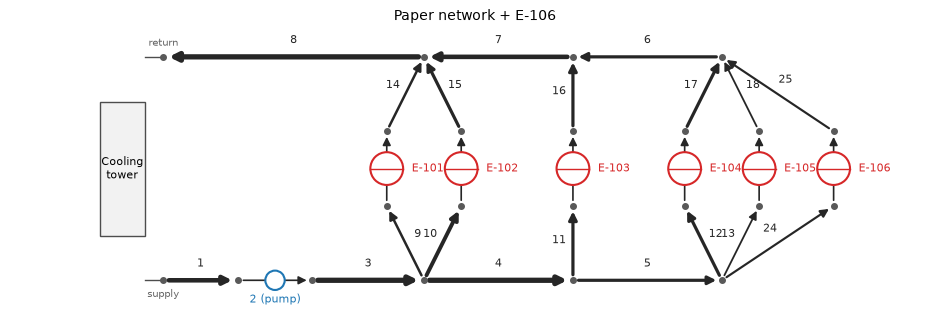

In [2]:
edges = list(base.network.edges) + [
    PipeEdge(id=24, tail=6, head=21, length_m=40.0, diameter_in=3.0),
    HeatExchangerEdge(id=26, tail=21, head=22, tag="E-106"),
    PipeEdge(id=25, tail=22, head=7, length_m=40.0, diameter_in=3.0),
]
layout = dict(base.network.layout)
layout.update({21: (9.0, 1.0), 22: (9.0, 2.0)})
network = base.network.model_copy(update={"edges": edges, "layout": layout})

# the cooler data (Tables 5-6 style). Fields left out fall back to `heat_exchanger_defaults`.
e106 = HeatExchangerSpec(
    area_m2=35.0,
    hot_flow_design_kg_s=4.0,
    water_flow_design_kg_s=8.0,
    hot_inlet_C=75.0,
    hot_outlet_spec_C=45.0,
    water_inlet_design_C=32.0,
    water_outlet_design_C=40.0,
    cp_hot_J_kgK=2300.0,
    h_water_design_W_m2K=5200.0,
    h_hot_design_W_m2K=400.0,
    fouling_m2K_W=5.0e-4,
    head_loss_design_m=2.5,
    penalty_factor_USD_per_C_y=20000.0,  # a more valuable product in this cooler
)
custom = CaseStudy(
    name="Paper network + E-106",
    network=network,
    heat_exchangers={**base.heat_exchangers, "E-106": e106},
    heat_exchanger_defaults=base.heat_exchanger_defaults,
    pipes=base.pipes,
    pumps=base.pumps,
    cooling_tower=base.cooling_tower.model_copy(update={"air_flow_kg_s": 70.0}),  # a slightly larger tower fan
    water=base.water,
    economics=base.economics.model_copy(update={"energy_cost_USD_kWh": 0.12}),
    scenarios=base.scenarios,
)
net = build_network(custom.network)
fig, ax = plt.subplots(figsize=(12, 5))
plot_network(custom, ax=ax, title=custom.name)
display(T.table_circuits(custom, net))

The configuration can be saved and later loaded with `load_case(...)` (or checked and run from
the shell with `coolingnet validate cases/example_six_coolers.yaml` and
`coolingnet run cases/example_six_coolers.yaml --out results_six_coolers`).

In [3]:
path = dump_case(custom, Path("../cases/example_six_coolers.yaml"))
reloaded = load_case(path)
assert reloaded == custom
print("saved to", path)

saved to ../cases/example_six_coolers.yaml


## 2. Simulate the current condition (hot flow rates +20 %)

In [4]:
sim = simulate_design(custom, hot_flow_factor=custom.scenarios.hot_flow_increase_factor)
pd.DataFrame(sim.exchangers).T[["k_kg_s", "T_hot_out_C", "T_hot_out_spec_C", "penalty_USD_y", "head_loss_m"]].astype(float).round(2)

,k_kg_s,T_hot_out_C,T_hot_out_spec_C,penalty_USD_y,head_loss_m
E-101,11.62,65.09,65.0,1155.36,5.38
E-102,28.14,81.49,80.0,18612.48,6.12
E-103,34.40,41.68,40.0,21015.03,4.52
E-104,13.56,43.16,41.0,27006.62,2.29
E-105,2.82,41.90,41.0,11191.33,1.01
E-106,5.71,51.24,45.0,124748.23,1.34


## 3. Optimize: valves only, then a finite budget

`optimize_debottlenecking` accepts `budget=None` (unlimited), `budget=0.0` (valves only) or a
positive value; `penalty_factor` and `hot_flow_factor` can also be overridden per call.

In [5]:
settings = SolverSettings(name="nlpbb", time_limit_s=600)
valves_only = optimize_debottlenecking(custom, budget=0.0, settings=settings)
budget_run = optimize_debottlenecking(custom, budget=4000.0, settings=settings, warm_start=valves_only)
current = simulate_existing_network(custom, custom.scenarios.hot_flow_increase_factor, settings=settings)
summary = T.table_costs({"current": current, "valves only": valves_only, "budget 4 kUSD/y": budget_run})
display(summary.round(2))
display(T.table_no_budget(current, valves_only).round(2))

,Pipe (kUSD/y),Pump (kUSD/y),Operating (kUSD/y),Penalty (kUSD/y),Objective (kUSD/y),Budget (kUSD/y),Pump option,Pipes changed,Solver status
Run,,,,,,,,,
current,0.00,0.0,24.07,203.73,227.80,NaN,1,0,optimal
valves only,0.00,0.0,24.75,180.73,205.47,0.0,1,0,optimal
budget 4 kUSD/y,3.92,0.0,24.18,150.43,178.53,4.0,1,4,optimal


,Current cooling water flow rate (kg/s),Optimal cooling water flow rate (kg/s),Valve head loss (m),Penalty (kUSD/y),Penalty variation (%)
E-101,11.62,11.07,3.73,1.15,-0.04
E-102,28.14,19.08,6.59,32.25,73.27
E-103,34.40,27.99,5.07,31.73,50.98
E-104,13.56,15.42,1.40,16.62,-38.46
E-105,2.82,3.22,1.35,0.00,-100.00
E-106,5.71,7.53,0.00,98.97,-20.66
Total,96.26,84.31,NaN,180.73,-11.29


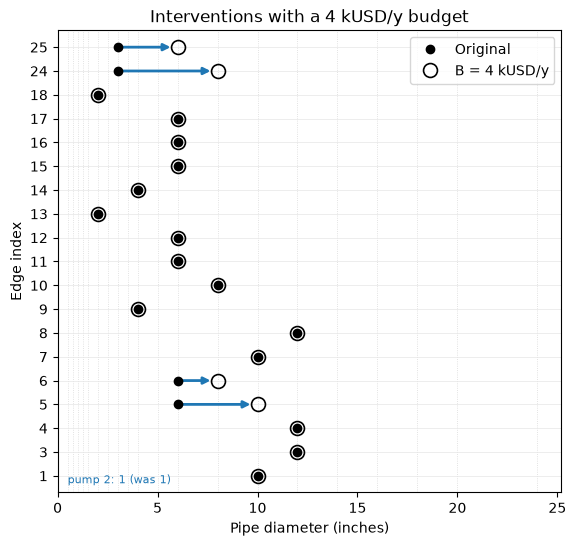

,k_kg_s,T_hot_out_C,T_hot_out_spec_C,valve_head_loss_m,penalty_USD_y
tag,,,,,
E-101,11.89,65.04,65.0,0.00,506.53
E-102,20.98,82.38,80.0,3.10,29719.55
E-103,30.53,42.29,40.0,1.28,28674.63
E-104,16.76,42.21,41.0,0.00,15107.90
E-105,3.41,41.00,41.0,0.21,0.00
E-106,11.62,48.82,45.0,0.00,76420.37


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
F.plot_diameter_dotchart(custom, budget_run, ax=ax, label="B = 4 kUSD/y", title="Interventions with a 4 kUSD/y budget", show_pump=True)
plt.show()
budget_run.exchangers_df()[["k_kg_s", "T_hot_out_C", "T_hot_out_spec_C", "valve_head_loss_m", "penalty_USD_y"]].round(2)